## Matplotlib

Matplotlib is Python's most widely used plotting library. Nearly every other plotting library in the Python ecosystem (including Seaborn, and the `.plot()` method of Pandas) is built on top of it. Almost everything you will ever want to plot lives in the `pyplot` submodule, which is imported like this:

```python
import matplotlib.pyplot as plt
```
Again, note the shortcut name "plt". Just like "np" and "pd", this is the standard notation you will see everywhere.

In older notebooks you will often see the line `%matplotlib inline` at the top. This tells Jupyter to render plots directly below the cell. In modern versions of Jupyter this is the default, so you don't need it anymore.

Let's make our first plot:

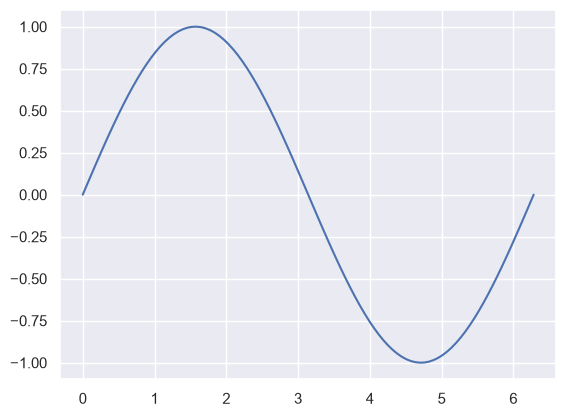

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 100) # 100 evenly spaced points between 0 and 2*pi
y = np.sin(x)

plt.plot(x, y)
plt.show()

`plt.plot` takes a sequence of x-values and a sequence of y-values and connects the points `(x[i], y[i])` with straight lines. Since we used 100 points, the lines are so short that the curve looks smooth. Notice that we passed Numpy arrays directly – Matplotlib works with Numpy arrays, Python lists and Pandas series alike.

Since each x-value needs exactly one y-value, both sequences must have the same length:

ValueError: x and y must have same first dimension, but have shapes (3,) and (2,)

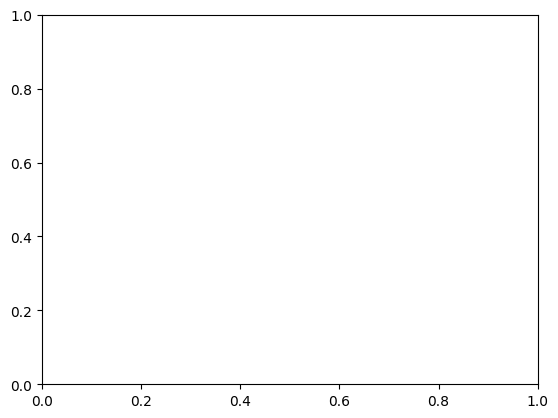

In [7]:
plt.plot([1, 2, 3], [1, 2]) # this will throw an error

A plot without labels is not very useful. Matplotlib lets us add axis labels, a title and a legend. We can also call `plt.plot` multiple times to draw several lines on the same plot. The `label` parameter tells the legend what to call each line:

In [ ]:
plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.cos(x), label="cos(x)")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Sine and Cosine")
plt.legend()
plt.show()

We can control how each line looks with parameters such as `color`, `linestyle`, `linewidth` and `marker`. Colors can be given by name (`"red"`), by hex code (`"#1f77b4"`), or by the shorthand `"C0"`, `"C1"`, ... which refer to Matplotlib's default color cycle.

In [ ]:
x_coarse = np.linspace(0, 2 * np.pi, 15)

plt.plot(x_coarse, np.sin(x_coarse), color="C0", linestyle="--", marker="o", label="dashed with circles")
plt.plot(x_coarse, np.cos(x_coarse), color="C3", linestyle=":", linewidth=3, label="dotted and thick")
plt.legend()
plt.show()

### Figures and Axes

So far we have used the so-called *pyplot interface*: we call functions like `plt.plot` and `plt.title`, and Matplotlib keeps track of "the current plot" behind the scenes. This is quick, but becomes confusing as soon as you have more than one plot.

It helps to know the two most important objects in Matplotlib:

 * the **Figure**, which is the whole image (the "canvas")
 * the **Axes**, which is a single plot inside the figure, with its own x-axis, y-axis, title, etc. (Don't confuse *Axes* with *axis* – one Axes object contains two axis objects!)

A figure can contain many axes. The recommended way of working is the *object-oriented interface*, where we create the figure and axes explicitly with `plt.subplots()` and then call methods on the axes object:

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4)) # figsize is (width, height) in inches

ax.plot(x, np.sin(x), label="sin(x)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Object-oriented interface")
ax.legend()
plt.show()

Notice that most functions just get a `set_` prefix: `plt.xlabel` becomes `ax.set_xlabel`, `plt.title` becomes `ax.set_title`, and so on. You can also set many properties at once with `ax.set(xlabel=..., ylabel=..., title=...)`.

The real benefit shows when we want multiple plots in one figure. `plt.subplots(nrows, ncols)` returns a Numpy array of axes, which we can index just like any other Numpy matrix:

In [ ]:
rng = np.random.default_rng(42) # a random number generator with a fixed seed, so results are reproducible

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
print(type(axes), axes.shape)

# Top left: line plot
axes[0, 0].plot(x, np.sin(x))
axes[0, 0].set_title("Line plot")

# Top right: scatter plot
a = rng.normal(size=200)
b = 2 * a + rng.normal(size=200)
axes[0, 1].scatter(a, b, alpha=0.5) # alpha controls transparency
axes[0, 1].set_title("Scatter plot")

# Bottom left: bar chart
axes[1, 0].bar(["A", "B", "C", "D"], [5, 3, 7, 2])
axes[1, 0].set_title("Bar chart")

# Bottom right: histogram
axes[1, 1].hist(rng.normal(size=1000), bins=30)
axes[1, 1].set_title("Histogram")

fig.tight_layout() # prevents titles and labels from overlapping
plt.show()

These four plot types – line, scatter, bar and histogram – will cover the vast majority of your plotting needs. Let's look at a few of them in more detail.

### Scatter plots

A scatter plot shows the relationship between two variables. Beyond x and y, we can encode additional variables in the color (`c`) and size (`s`) of the markers. When colors encode a number, a **colorbar** tells the reader what the colors mean:

In [ ]:
n = 150
x_pts = rng.uniform(0, 10, n)
y_pts = rng.uniform(0, 10, n)
values = x_pts + y_pts          # a third variable, encoded as color
sizes = rng.uniform(10, 200, n) # a fourth variable, encoded as size

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(x_pts, y_pts, c=values, s=sizes, cmap="viridis", alpha=0.7)
fig.colorbar(sc, ax=ax, label="x + y")
ax.set(xlabel="x", ylabel="y", title="Color and size as extra dimensions")
plt.show()

The `cmap` parameter selects a **colormap**. Matplotlib has [many colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html). As a rule of thumb: use a *sequential* colormap (like `viridis`) for values that go from low to high, and a *diverging* colormap (like `coolwarm`) for values that deviate in both directions from a meaningful center, such as 0. Avoid `jet` and `rainbow` – they are not perceptually uniform and can mislead the reader.

### Histograms

A histogram shows the distribution of a single variable by sorting values into bins and counting how many values fall into each bin. The number of bins can change the story a lot:

In [ ]:
data = rng.normal(loc=170, scale=10, size=500) # e.g. body heights in cm

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, bins in zip(axes, [5, 25, 200]):
    ax.hist(data, bins=bins, edgecolor="white")
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("height [cm]")
axes[0].set_ylabel("count")
fig.tight_layout()
plt.show()

With too few bins we lose the shape of the distribution, with too many bins we mostly see noise. There is no universally correct number, so try a few!

We can also add reference lines to a plot. `ax.axvline` draws a vertical line and `ax.axhline` draws a horizontal line across the whole axes – handy for marking means, thresholds or observed values:

In [ ]:
fig, ax = plt.subplots()
ax.hist(data, bins=25, edgecolor="white")
ax.axvline(data.mean(), color="C3", linestyle="--", label=f"mean = {data.mean():.1f}")
ax.set(xlabel="height [cm]", ylabel="count")
ax.legend()
plt.show()

### Displaying matrices

Since images are just matrices of numbers, Matplotlib can display any 2D Numpy array as an image with `imshow`. This is very useful for looking at matrices like the ones we built with Numpy:

In [ ]:
M = np.arange(1, 17).reshape(4, 4)
print(M)

fig, ax = plt.subplots()
im = ax.imshow(M, cmap="viridis")
fig.colorbar(im, ax=ax)
ax.set_title("A 4x4 matrix as an image")
plt.show()

### Customizing and saving

Every part of a plot can be customized. Some of the most commonly needed options are axis limits, ticks, grids and log scales:

In [ ]:
xs = np.linspace(1, 100, 200)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, xs**2, label="$x^2$")       # Matplotlib understands LaTeX between $ signs!
ax.plot(xs, np.exp(xs / 10), label="$e^{x/10}$")
ax.set_yscale("log")                    # logarithmic y-axis
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False) # remove the box around the plot
ax.legend()
plt.show()

Finally, to use a plot in a report or presentation, save it with `fig.savefig`. The file format is inferred from the file extension. Use a vector format like `.pdf` or `.svg` when possible, as these stay sharp at any zoom level. For raster formats like `.png`, increase the `dpi` (dots per inch) for a higher resolution. `bbox_inches="tight"` removes unnecessary white space around the figure.

```python
fig.savefig("my_plot.png", dpi=300, bbox_inches="tight")
fig.savefig("my_plot.pdf", bbox_inches="tight")
```

Note that you should call `savefig` *before* `plt.show()`, since showing a figure "uses it up" in many environments.

## Matplotlib Exercises

Plot the functions $f(x) = x^2$, $g(x) = x^3$ and $h(x) = \sqrt{x}$ for $x \in [0, 2]$ in a single axes. Then:

- Give each function a different color and line style.
- Add axis labels, a title and a legend.
- Add a horizontal dashed line at $y = 1$.

You may need to look at the official <a href=https://matplotlib.org/stable/api/pyplot_summary.html>Matplotlib documentation</a>.

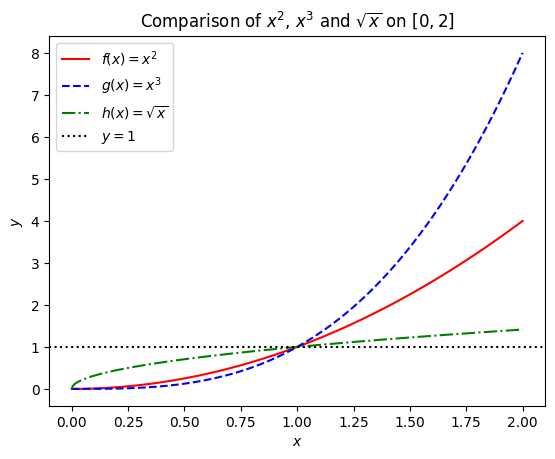

In [ ]:
x = np.linspace(0, 2, 400)

plt.plot(x, x**2, "r-",  label=r"$f(x) = x^2$")
plt.plot(x, x**3, "b--", label=r"$g(x) = x^3$")
plt.plot(x, np.sqrt(x), "g-.", label=r"$h(x) = \sqrt{x}$")
plt.axhline(1, color="k", linestyle=":", label=r"$y = 1$")

plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.title("Comparison of $x^2$, $x^3$ and $\\sqrt{x}$ on $[0, 2]$")
plt.legend()
plt.show()

Draw 1000 samples from a normal distribution with mean 5 and standard deviation 2, and 1000 samples from an exponential distribution with scale 2 (use `np.random.default_rng`). Create a figure with **1 row and 2 columns** of axes. Then:

- In the left axes, plot a histogram of each sample in the same axes (use transparency so both are visible) and add a legend.
- In the right axes, make a scatter plot of the normal samples (x) against the exponential samples (y).
- Mark the mean of each sample with a vertical line in the left axes.
- Give each axes a title and save the figure as `exercise.png`.

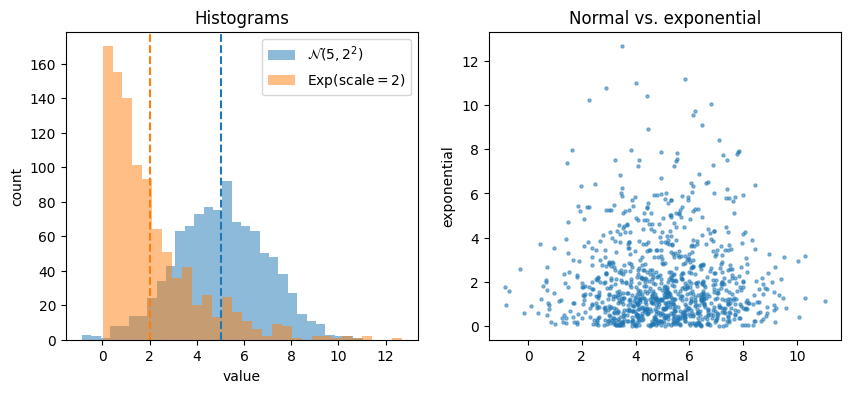

In [8]:
rng = np.random.default_rng()
a = rng.normal(5, 2, 1000)
b = rng.exponential(2, 1000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.hist(a, bins=30, alpha=0.5, color="C0", label=r"$\mathcal{N}(5, 2^2)$")
ax1.hist(b, bins=30, alpha=0.5, color="C1", label=r"$\mathrm{Exp}(\mathrm{scale}=2)$")
ax1.axvline(a.mean(), color="C0", linestyle="--")
ax1.axvline(b.mean(), color="C1", linestyle="--")
ax1.set(title="Histograms", xlabel="value", ylabel="count")
ax1.legend()

ax2.scatter(a, b, s=5, alpha=0.5)
ax2.set(title="Normal vs. exponential", xlabel="normal", ylabel="exponential")

fig.savefig("exercise.png", dpi=150)

## Seaborn

Matplotlib can draw anything, but it is quite low-level: we have to tell it exactly what to draw, and things like grouping data by category, computing averages or adding error bars are up to us. [Seaborn](https://seaborn.pydata.org) is a library built on top of Matplotlib that is designed for *statistical* visualization. It works directly with Pandas data frames and does a lot of this work for us.

Seaborn is imported like this:

```python
import seaborn as sns
```

The abbreviation "sns" is a bit of an inside joke (it's the initials of Samuel Norman Seaborn, a character from the TV show *The West Wing*), but it is the standard you will see everywhere.

When you work with Seaborn, it's handy to have the [tutorial](https://seaborn.pydata.org/tutorial.html) and the [example gallery](https://seaborn.pydata.org/examples/index.html) lying around.

Seaborn should already be part of your anaconda installation. If not, simply run:

```
$ conda install seaborn
```

Calling `sns.set_theme()` switches to Seaborn's default style, which also changes the look of plain Matplotlib plots:

In [4]:
import pandas as pd
import seaborn as sns

sns.set_theme()

### Our dataset

Seaborn comes with a number of example datasets that can be loaded with `sns.load_dataset("tips")`, `sns.load_dataset("penguins")`, etc. These are downloaded from the internet, though. To make sure this notebook works offline, we will instead generate our own data frame with Numpy. You don't need to understand every line in the next cell – it creates a (made-up) dataset of students with their major, semester, weekly study hours, hours of sleep and exam score.

In [6]:
rng = np.random.default_rng(0)
n = 300

major = rng.choice(["Informatics", "Mathematics", "Physics", "Economics"], size=n, p=[0.4, 0.2, 0.2, 0.2])
semester = rng.choice(["Bachelor", "Master"], size=n, p=[0.7, 0.3])
study_hours = rng.gamma(shape=4, scale=3, size=n).round(1)
sleep_hours = rng.normal(7, 1, size=n).clip(4, 10).round(1)

major_bonus = pd.Series(major).map({"Informatics": 0, "Mathematics": -4, "Physics": -2, "Economics": 3}).values
score = (40 + 1.5 * study_hours + 2.5 * (sleep_hours - 7) + major_bonus
         + 5 * (semester == "Master") + rng.normal(0, 8, size=n)).clip(0, 100).round(1)

students = pd.DataFrame({
    "major": major,
    "semester": semester,
    "study_hours": study_hours,
    "sleep_hours": sleep_hours,
    "score": score,
})
students.head()

,major,semester,study_hours,sleep_hours,score
0,Physics,Master,10.4,8.0,59.6
1,Informatics,Bachelor,6.7,6.1,52.1
2,Informatics,Bachelor,6.1,7.9,57.9
3,Informatics,Master,4.4,7.0,57.0
4,Economics,Bachelor,11.2,7.2,46.3


Note how this data frame is organized: each **row** is one observation (one student) and each **column** is one variable. This is called *long-form* or *tidy* data, and it is the format Seaborn expects. Instead of passing arrays, we pass the data frame as `data` and tell Seaborn which *column names* to put on which axis.

### Distributions

The Seaborn equivalent of a histogram is `histplot`. Setting `kde=True` additionally draws a smooth estimate of the distribution (a *kernel density estimate*):

In [ ]:
sns.histplot(data=students, x="score", kde=True)
plt.show()

Here comes the first big advantage of Seaborn. With the `hue` parameter, we can split the data by a categorical column, and Seaborn automatically picks colors and adds a legend:

In [ ]:
sns.histplot(data=students, x="score", hue="semester", kde=True)
plt.show()

Doing the same in plain Matplotlib would require us to filter the data frame for each category, call `hist` once per category, pick colors and build the legend ourselves.

Notice that there are many more Bachelor than Master students, which makes the two distributions hard to compare. We can normalize each group separately with `stat="density"` and `common_norm=False`:

In [ ]:
sns.histplot(data=students, x="score", hue="semester", kde=True, stat="density", common_norm=False)
plt.show()

### Relationships

To look at the relationship between two numerical variables, we use `scatterplot`. Again, `hue`, `size` and `style` let us encode more variables:

In [ ]:
sns.scatterplot(data=students, x="study_hours", y="score", hue="major", style="semester")
plt.show()

If we suspect a linear relationship, `regplot` draws a scatter plot together with a fitted regression line. The shaded band around the line is a 95% confidence interval for the regression:

In [ ]:
sns.regplot(data=students, x="study_hours", y="score")
plt.show()

A quick way to see how *all* numerical variables relate to each other is a heatmap of the correlation matrix. Remember that `students.corr()` is a data frame itself, so we can pass it directly to `heatmap`:

In [ ]:
corr = students.corr(numeric_only=True)
corr

In [ ]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

Note that we use a diverging colormap here, since correlations range from -1 to 1 with 0 as the natural center, and we fix `vmin` and `vmax` so that the colors always mean the same thing.

An even more complete overview is the `pairplot`, which shows a scatter plot for every pair of numerical columns and the distribution of each column on the diagonal. It is a great first step when exploring a new dataset:

In [ ]:
sns.pairplot(data=students, hue="semester")
plt.show()

### Categorical data

Often we want to compare a numerical variable across categories. A **box plot** shows the median (center line), the interquartile range (the box, from the 25% to the 75% quantile), the range of the rest of the data (the "whiskers"), and outliers as individual points:

In [ ]:
sns.boxplot(data=students, x="major", y="score")
plt.show()

A **violin plot** shows the full shape of the distribution of each category instead. With `hue` and `split=True`, we can compare two groups within each category:

In [ ]:
sns.violinplot(data=students, x="major", y="score", hue="semester", split=True)
plt.show()

A **bar plot** in Seaborn does something you need to be aware of: it *aggregates* the data. By default, each bar shows the **mean** of the y-variable for that category, and the black line is a 95% confidence interval for that mean (computed by bootstrapping):

In [ ]:
sns.barplot(data=students, x="major", y="score")
plt.show()

We can change the aggregation with the `estimator` parameter and the error bars with `errorbar`, e.g. `errorbar="sd"` to show the standard deviation instead. Let's compare this to the actual means:

In [ ]:
print(students.groupby("major")["score"].mean())

sns.barplot(data=students, x="major", y="score", estimator="median", errorbar="sd")
plt.show()

If you just want to count how many rows fall into each category, use `countplot`:

In [ ]:
sns.countplot(data=students, x="major", hue="semester")
plt.show()

### Seaborn and Matplotlib together

All of the functions above are so-called **axes-level** functions: they draw into a single Matplotlib axes and return it. This means we can use everything we learned about Matplotlib to customize the result, and we can pass `ax=` to place Seaborn plots into our own subplots:

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=students, x="semester", y="study_hours", ax=axes[0])
axes[0].set_title("Study hours by degree")

ax = sns.regplot(data=students, x="sleep_hours", y="score", ax=axes[1], scatter_kws={"alpha": 0.4})
ax.set(xlabel="sleep per night [h]", ylabel="exam score", title="Sleep vs. score")

fig.tight_layout()
plt.show()

Seaborn also has **figure-level** functions: `relplot` (relationships), `displot` (distributions) and `catplot` (categorical). They create a whole figure on their own and can split the data into multiple subplots (called *facets*) with the `col` and `row` parameters. The `kind` parameter selects the type of plot:

In [ ]:
sns.relplot(data=students, x="study_hours", y="score", hue="semester", col="major", col_wrap=2, kind="scatter")
plt.show()

In [ ]:
sns.catplot(data=students, x="major", y="score", col="semester", kind="box")
plt.show()

Similarly, `lmplot` is the figure-level version of `regplot`. With `hue`, it fits one regression line per group:

In [ ]:
sns.lmplot(data=students, x="study_hours", y="score", hue="semester")
plt.show()

Because figure-level functions create their own figure, they **cannot** be placed into existing subplots with `ax=`. Use axes-level functions when you want to combine Seaborn plots with your own Matplotlib layout, and figure-level functions for quick faceted overviews.

### Wide-form vs. long-form data

Sometimes data comes in *wide form*, where each column holds the same kind of measurement for a different group. For example, here are the scores of three exams:

In [ ]:
exams = pd.DataFrame({
    "exam_1": rng.normal(60, 10, 50).round(1),
    "exam_2": rng.normal(65, 12, 50).round(1),
    "exam_3": rng.normal(70, 8, 50).round(1),
})
exams.head()

Seaborn can plot some wide-form data directly (try `sns.boxplot(data=exams)`), but to use features like `hue` and `col` we need long form. Pandas' `melt` turns columns into rows:

In [ ]:
exams_long = exams.melt(var_name="exam", value_name="score")
print(exams_long.shape)
exams_long.head()

In [ ]:
sns.boxplot(data=exams_long, x="exam", y="score")
plt.show()

## Seaborn Exercises

Using the `students` data frame:

- Add a new column `study_level` that is `"low"` for students with fewer than 10 study hours, `"medium"` for 10–15 hours and `"high"` for more than 15 hours (hint: `pd.cut`).
- Create a box plot of `score` for each `study_level`, with the levels in a sensible order (hint: the `order` parameter).
- Create a scatter plot of `sleep_hours` against `score`, colored by `study_level`.
- Place both plots side by side in a single figure with proper titles.

You may need to look at the official <a href=https://seaborn.pydata.org/api.html>Seaborn documentation</a>.

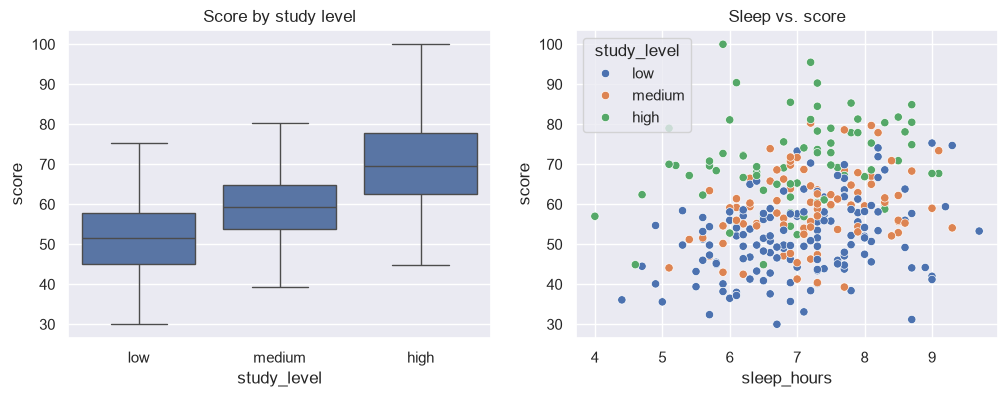

In [12]:
students["study_level"] = pd.cut(students["study_hours"], bins=[0, 10, 15, np.inf],
                                 labels=["low", "medium", "high"])
order = ["low", "medium", "high"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=students, x="study_level", y="score", order=order, ax=axes[0])
axes[0].set_title("Score by study level")

sns.scatterplot(data=students, x="sleep_hours", y="score",
                hue="study_level", hue_order=order, ax=axes[1])
axes[1].set_title("Sleep vs. score")

plt.show()

Using the `students` data frame:

- Use `displot` to show the distribution of `study_hours`, with one facet per `major`.
- Use `catplot` with `kind="bar"` to show the mean `score` per `major`, split by `semester` with `hue`.
- Which major has the highest average score? Is the difference between Bachelor and Master students similar across majors? Look at the confidence intervals – which differences would you trust?

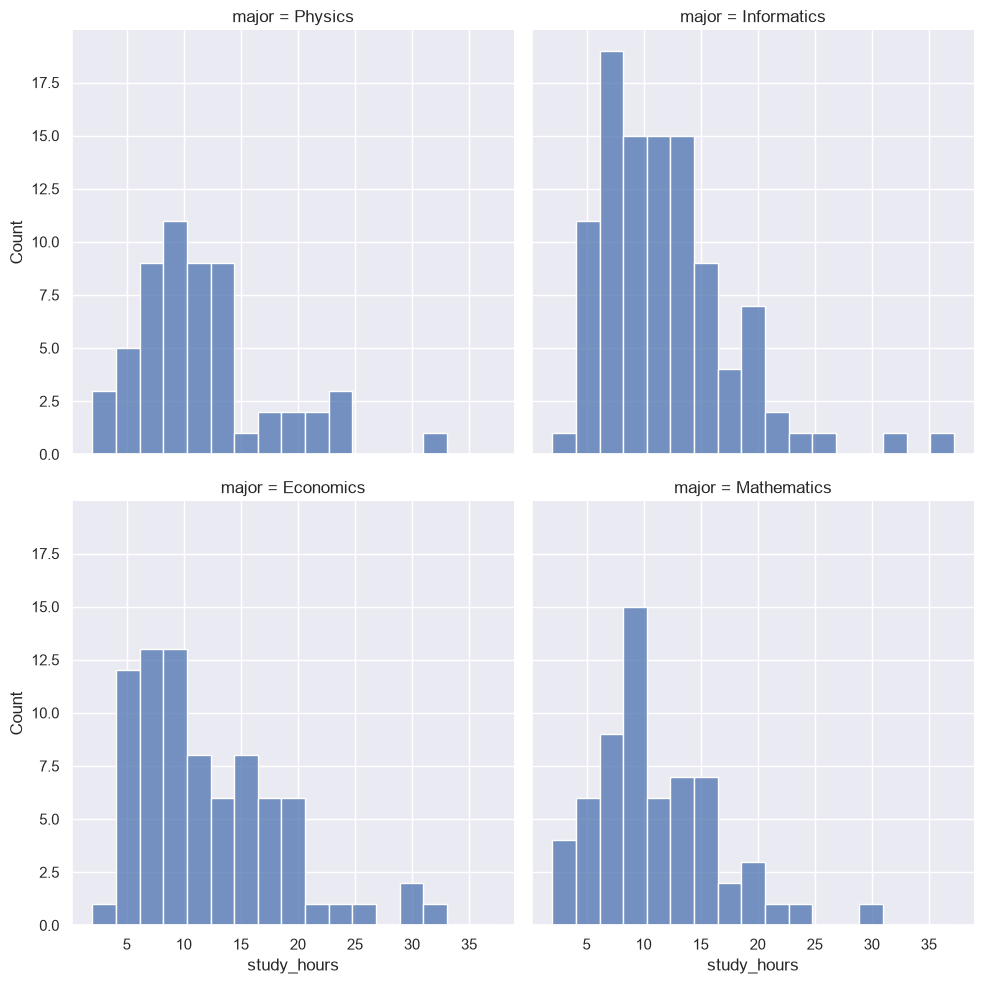

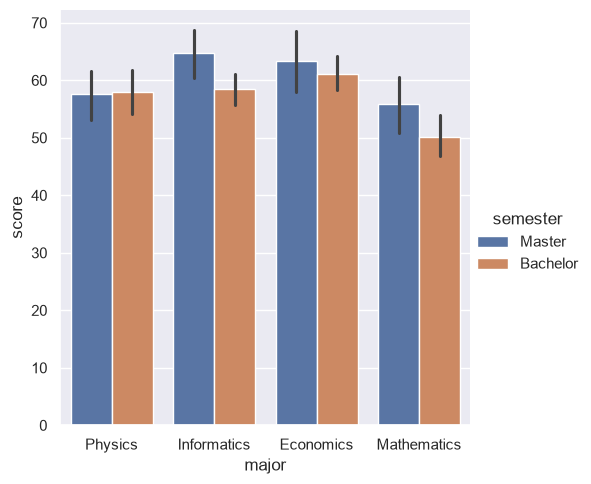

In [ ]:
sns.displot(data=students, x="study_hours", col="major", col_wrap=2)
sns.catplot(data=students, x="major", y="score", hue="semester", kind="bar")
plt.show()

Economics has the highest average score (about 61.8). The difference between Bachelor and Master is small in Physics and Economics and the confidence intervals mostly overlap, so there is not much evidence that there is a real difference between them, whereas in Informatics and Mathematics the intervals overlap much less, suggesting there could be a real difference in the score distribution.

## Visualizing the A - B test

Let's return to the slogan experiment from the last exercise. As a reminder: $N_A = 6000$ ads showed Slogan A and got $n_A = 1700$ clicks, and $N_B = 6000$ ads showed Slogan B and got $n_B = 2100$ clicks.

A z-statistic and a p-value are compact, but a good plot can make the result much more convincing to your marketing department. In this exercise we will *simulate* what the experiment would look like if the null hypothesis were true.

In [15]:
N_A, n_A = 6000, 1700
N_B, n_B = 6000, 2100

### Part 1

Create a bar plot showing the click-through rates $p_A$ and $p_B$ of the two slogans. Add error bars showing the standard error of each rate, $\sqrt{p(1-p)/N}$ (hint: the `yerr` parameter of `ax.bar`). Label the axes and give the plot a title.

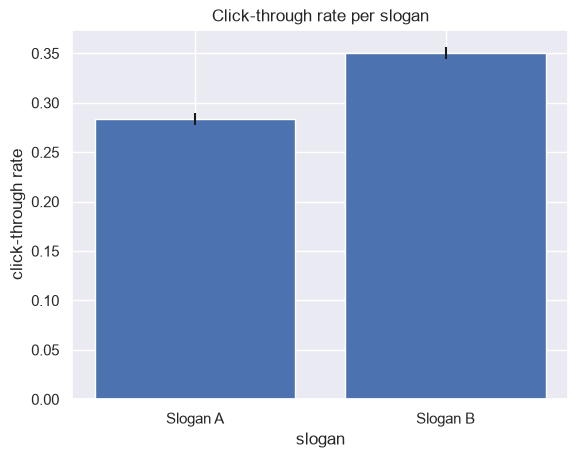

In [17]:
p_A, p_B = n_A / N_A, n_B / N_B
se = [np.sqrt(p * (1 - p) / N) for p, N in [(p_A, N_A), (p_B, N_B)]]

fig, ax = plt.subplots()
ax.bar(["Slogan A", "Slogan B"], [p_A, p_B], yerr=se)
ax.set(xlabel="slogan", ylabel="click-through rate", title="Click-through rate per slogan")
plt.show()

### Part 2

Under the null hypothesis, both slogans have the same click probability $p = \frac{n_A + n_B}{N_A + N_B}$. Simulate 10,000 experiments under this assumption: in each one, draw the number of clicks for A and for B from a binomial distribution (`rng.binomial(N, p, size=10_000)`) and compute the difference $\hat p_A - \hat p_B$.

Then:

- Plot a histogram of the 10,000 simulated differences.
- Overlay the normal distribution with mean 0 and standard deviation $\sqrt{p(1-p) \left( \frac{1}{N_A} + \frac{1}{N_B} \right)}$ (hint: `scipy.stats.norm.pdf`, and use `stat="density"` in `sns.histplot`).
- Mark the *observed* difference $p_A - p_B$ with a vertical line.

You may need to adjust the x-axis limits so that the observed difference is visible.

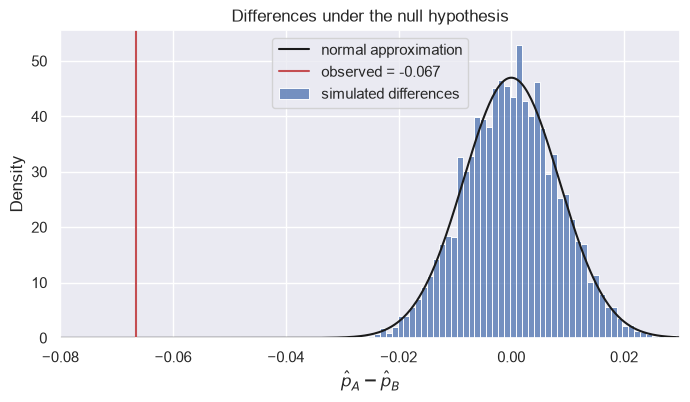

In [23]:
from scipy.stats import norm

rng = np.random.default_rng(0)
p = (n_A + n_B) / (N_A + N_B)
diff = rng.binomial(N_A, p, 10_000) / N_A - rng.binomial(N_B, p, 10_000) / N_B
sd = np.sqrt(p * (1 - p) * (1 / N_A + 1 / N_B))
obs = p_A - p_B

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(diff, stat="density", ax=ax, label="simulated differences")
xs = np.linspace(-0.08, 0.03, 400)
ax.plot(xs, norm.pdf(xs, 0, sd), "k", label="normal approximation")
ax.axvline(obs, color="C3", label=f"observed = {obs:.3f}")
ax.set(xlabel=r"$\hat p_A - \hat p_B$", title="Differences under the null hypothesis")
ax.set_xlim(-0.08, 0.03)
ax.legend()
plt.show()

### Part 3

Describe what the plot shows. Where does the observed difference lie relative to the simulated differences? How does this relate to the z-statistic and p-value you computed in the last exercise?

Under the null hypothesis, the simulated differences are centered at 0 and closely follow the normal curve. The observed difference is -0.067, far below any of the simulated values. This is consistent with the computed z-statistic showing that the oberved value lies about 7.8 standard deviations below zero and the p-value telling us that the chance of a value under the null hypthesis landing as low as the oberved value is extremely unlikely.